In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Atividade 2 (horas que mulheres trabalham em serviços domésticos)

In [2]:
bruto = pd.read_excel("Tabela 1.1.1.xls", engine="xlrd", header=None)
indicador_1 = bruto.iloc[8:41].copy()
indicador_1.columns = [
    "uf_regiao",
    "total",
    "total_branca",
    "total_preta_parda",
    "homem_branca",
    "homem_preta_parda",
    "mulher_branca",
    "mulher_preta_parda",
]
indicador_1 = indicador_1.reset_index(drop=True)
for col in indicador_1.columns[1:]:
    indicador_1[col] = pd.to_numeric(indicador_1[col], errors="coerce")
regioes = ["Norte", "Nordeste", "Sudeste", "Sul", "Centro-Oeste"]

In [3]:
reg = indicador_1[indicador_1["uf_regiao"].isin(regioes)].copy()
reg["homens"] = (reg["homem_branca"] + reg["homem_preta_parda"]) / 2
reg["mulheres"] = (reg["mulher_branca"] + reg["mulher_preta_parda"]) / 2

reg_long = reg.melt(
    id_vars="uf_regiao",
    value_vars=["homens", "mulheres"],
    var_name="sexo",
    value_name="horas",
)
reg_long

,uf_regiao,sexo,horas
0,Norte,homens,11.551649
1,Nordeste,homens,11.786171
2,Sudeste,homens,12.057182
3,Sul,homens,11.353058
4,Centro-Oeste,homens,10.439429
5,Norte,mulheres,19.914984
6,Nordeste,mulheres,23.230691
7,Sudeste,mulheres,21.361700
8,Sul,mulheres,19.175851
9,Centro-Oeste,mulheres,18.775862


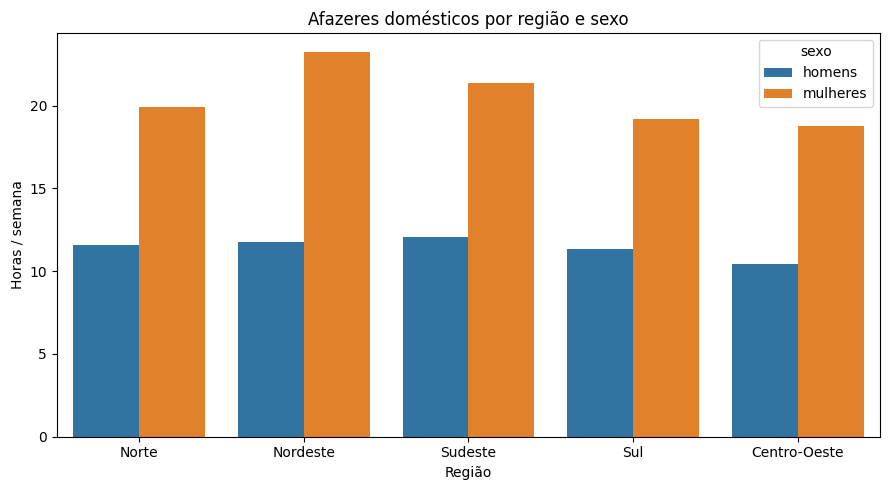

In [4]:
fig, ax = plt.subplots(figsize=(9, 5))
sns.barplot(data=reg_long, x="uf_regiao", y="horas", hue="sexo", ax=ax)
ax.set_title("Afazeres domésticos por região e sexo")
ax.set_xlabel("Região")
ax.set_ylabel("Horas / semana")
plt.tight_layout()
plt.show()

# Atividade 3 (formação acadêmica)

In [5]:
bruto3 = pd.read_excel("Tabela_3_Areas_gerais_de_formacao_na_graduacao.xlsx", header=None)


formacao_total = bruto3.iloc[3:9, [0, 1, 2, 3]].copy()
formacao_total.columns = ["uf_regiao", "total", "homens", "mulheres"]

formacao_stem = bruto3.iloc[3:9, [0, 4, 5, 6]].copy()
formacao_stem.columns = ["uf_regiao", "total", "homens", "mulheres"]

formacao_saude = bruto3.iloc[3:9, [0, 7, 8, 9]].copy()
formacao_saude.columns = ["uf_regiao", "total", "homens", "mulheres"]

for tabela in [formacao_total, formacao_stem, formacao_saude]:
    for col in ["total", "homens", "mulheres"]:
        tabela[col] = pd.to_numeric(tabela[col], errors="coerce")
formacao_total

,uf_regiao,total,homens,mulheres
3,Brasil,25854291,10478534,15375757
4,Norte,1525166,590558,934609
5,Nordeste,4748933,1744994,3003939
6,Sudeste,12828829,5391638,7437191
7,Sul,4338861,1768855,2570005
8,Centro-Oeste,2412502,982489,1430013


In [6]:
brasil = pd.DataFrame(
    {
        "area": ["Graduação (total)", "STEM", "Saúde / educação"],
        "homens": [
            formacao_total.loc[formacao_total["uf_regiao"] == "Brasil", "homens"].item(),
            formacao_stem.loc[formacao_stem["uf_regiao"] == "Brasil", "homens"].item(),
            formacao_saude.loc[formacao_saude["uf_regiao"] == "Brasil", "homens"].item(),
        ],
        "mulheres": [
            formacao_total.loc[formacao_total["uf_regiao"] == "Brasil", "mulheres"].item(),
            formacao_stem.loc[formacao_stem["uf_regiao"] == "Brasil", "mulheres"].item(),
            formacao_saude.loc[formacao_saude["uf_regiao"] == "Brasil", "mulheres"].item(),
        ],
    }
)
brasil_long = brasil.melt(id_vars="area", var_name="sexo", value_name="pessoas")
brasil_long

,area,sexo,pessoas
0,Graduação (total),homens,10478534
1,STEM,homens,2750422
2,Saúde / educação,homens,1677985
3,Graduação (total),mulheres,15375757
4,STEM,mulheres,1398619
5,Saúde / educação,mulheres,6401723


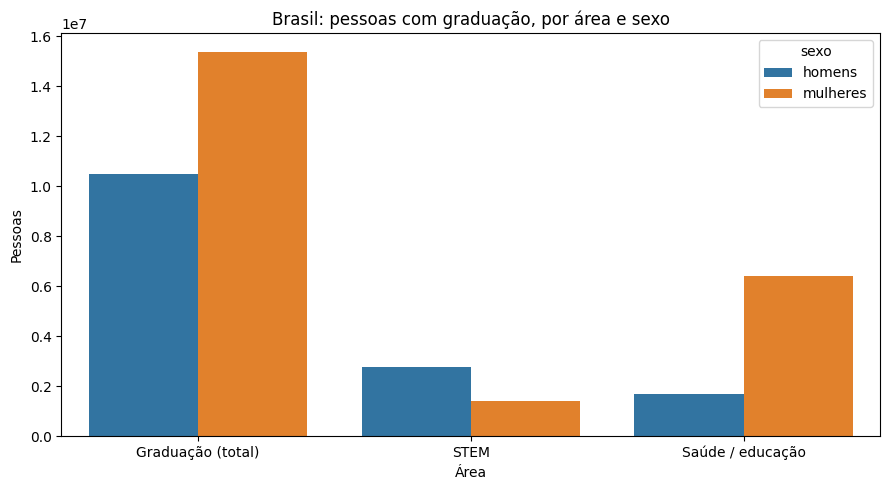

In [7]:
fig, ax = plt.subplots(figsize=(9, 5))
sns.barplot(data=brasil_long, x="area", y="pessoas", hue="sexo", ax=ax)
ax.set_title("Brasil: pessoas com graduação, por área e sexo")
ax.set_xlabel("Área")
ax.set_ylabel("Pessoas")
plt.tight_layout()
plt.show()

# Atividade 4 (população)

In [8]:
bruto4 = pd.read_excel("CD2022_Populacao_2010_Compatibilizada_20231222.xlsx", header=None)
pop = bruto4.iloc[3:, 1:].copy()
pop.columns = ["UF", "cod_uf", "cod_municipio", "municipio", "pop_2010_sinopse", "2010", "2022"]
pop = pop[pop["municipio"].notna()]
for col in ["2010", "2022"]:
    pop[col] = pd.to_numeric(pop[col], errors="coerce")

pop_estado = (
    pop.groupby("UF")[["2010", "2022"]]
    .sum()
    .reset_index()
)
pop_estado

,UF,2010,2022
0,AC,733559,830018
1,AL,3120887,3127683
2,AM,3483985,3941613
3,AP,669526,733759
4,BA,14017071,14141626
5,CE,8451644,8794957
6,DF,2572159,2817381
7,ES,3514952,3833712
8,GO,6001789,7056495
9,MA,6574789,6776699


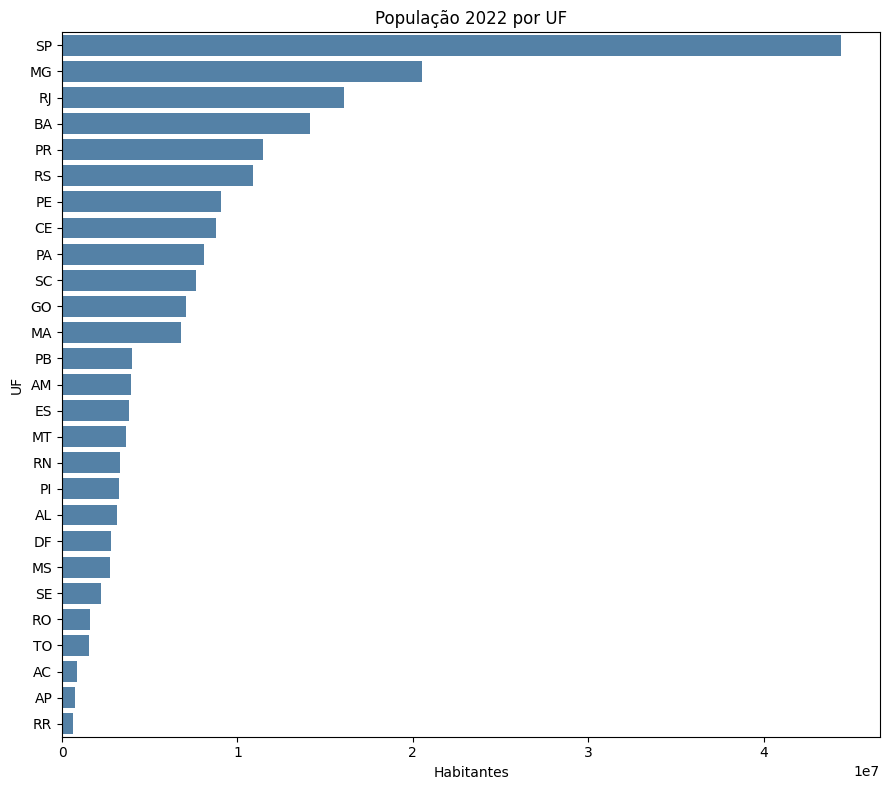

In [9]:
fig, ax = plt.subplots(figsize=(9, 8))
ordem = pop_estado.sort_values("2022", ascending=False)
sns.barplot(data=ordem, y="UF", x="2022", ax=ax, color="steelblue")
ax.set_title("População 2022 por UF")
ax.set_xlabel("Habitantes")
ax.set_ylabel("UF")
plt.tight_layout()
plt.show()